# Question 1: Object Detection with YOLOv5 (Using Pretrained Weights)
### Detect objects using pre-trained YOLOv5 model.

In [1]:
# Check the input images for object detection
from pathlib import Path

image_dir=Path("Dataset/Q1_YOLOv5/images")
image_paths=sorted(image_dir.glob("*.jpg"))

print("Total Images:", len(image_paths))
print("Image Files:", [img.name for img in image_paths])

Total Images: 2
Image Files: ['bus.jpg', 'zidane.jpg']


In [2]:
# Load the pretrained YOLOv5 model
import torch
model=torch.hub.load("ultralytics/yolov5","yolov5s",pretrained=True)
print("YOLOv5 model loaded successfully.")

Using cache found in C:\Users\Lenovo/.cache\torch\hub\ultralytics_yolov5_master
C:\Anaconda3\envs\aidl\Lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


YOLOv5  2026-11-4 Python-3.12.15 torch-2.14.1+cpu CPU



100%|██████████| 14.1M/14.1M [00:08<00:00, 1.75MB/s]

Fusing layers... 
YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
Adding AutoShape... 
YOLOv5 model loaded successfully.


image 1/2: 1080x810 4 persons, 1 bus
image 2/2: 720x1280 2 persons, 1 tie
Speed: 70.0ms pre-process, 815.3ms inference, 10.1ms NMS per image at shape (2, 3, 640, 640)


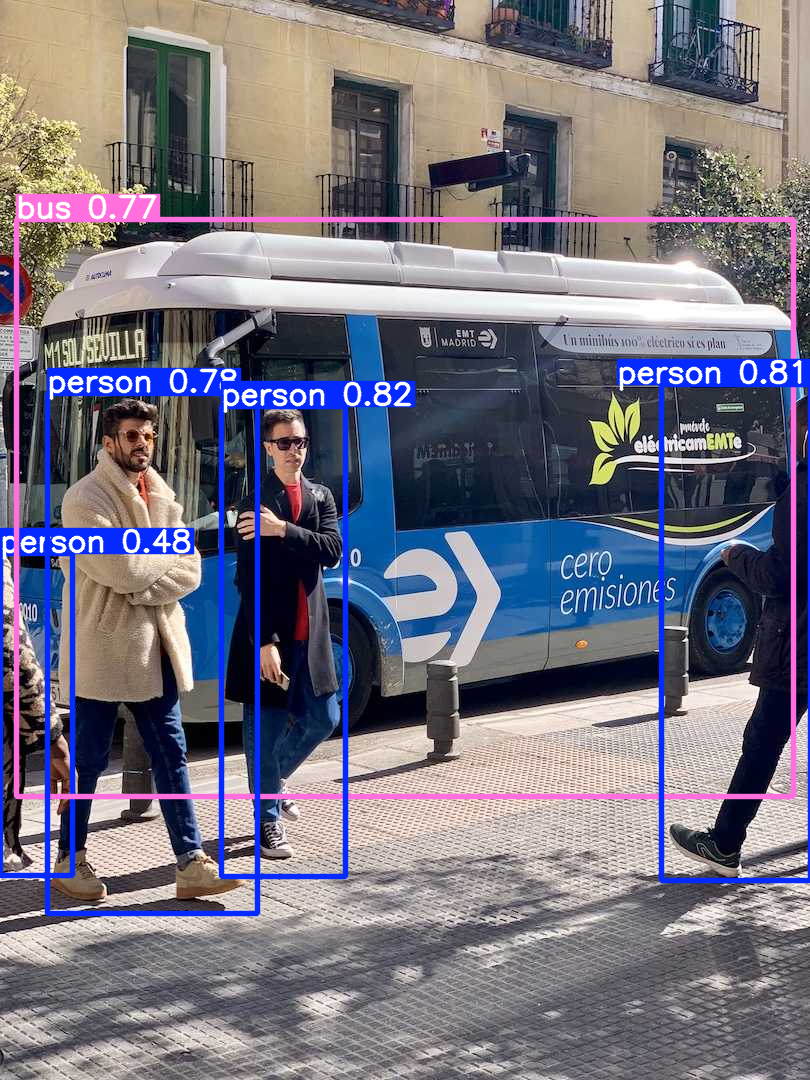

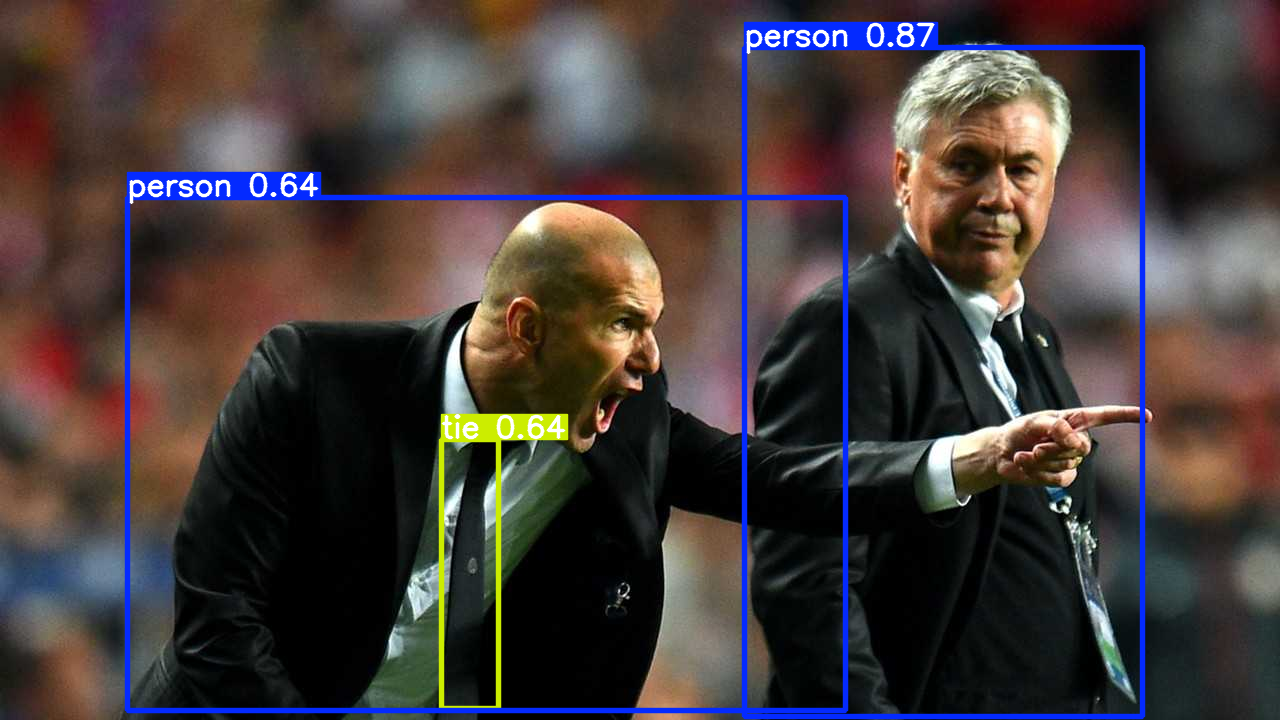

In [3]:
# Filter low-confidence detections and display results
model.conf=0.40
results=model([str(img) for img in image_paths])
results.print()
results.show()

# Question 2: Preprocessing Image for ResNet Input
### Write a function to preprocess image for pretrained ResNet.

In [4]:
# Check the input image for ResNet preprocessing
from pathlib import Path
image_path=Path("Dataset/Q2_ResNet/images/sunflower.jpg")

print("Image Exists:", image_path.exists())
print("Image File:", image_path.name)

Image Exists: True
Image File: sunflower.jpg


In [5]:
# Load the pretrained ResNet50 model
from tensorflow.keras.applications import ResNet50
model=ResNet50(weights="imagenet")
print("ResNet50 model loaded successfully.")

ResNet50 model loaded successfully.


In [6]:
# Define a function to preprocess an image for ResNet
import numpy as np
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.resnet50 import preprocess_input

def preprocess_image(image_path):
    img=image.load_img(image_path,target_size=(224,224))
    img_array=image.img_to_array(img)
    img_array=np.expand_dims(img_array,axis=0)
    img_array=preprocess_input(img_array)
    return img_array

img_array=preprocess_image(image_path)
print("Preprocessed Image Shape:", img_array.shape)

Preprocessed Image Shape: (1, 224, 224, 3)


# Question 3: CNN for CIFAR-10 Classification
### Build a CNN model to classify CIFAR-10 images.

In [7]:
# Check the CIFAR-10 dataset files
from pathlib import Path
data_dir=Path("Dataset/Q3_CIFAR10/cifar-10-batches-py")

print("Dataset Exists:", data_dir.exists())
print("Dataset Files:", sorted(file.name for file in data_dir.iterdir()))

Dataset Exists: True
Dataset Files: ['batches.meta', 'data_batch_1', 'data_batch_2', 'data_batch_3', 'data_batch_4', 'data_batch_5', 'readme.html', 'test_batch']


In [8]:
# Load the CIFAR-10 training dataset
import pickle
import numpy as np

X_train_batches=[]
y_train_batches=[]

for i in range(1,6):
    with open(data_dir/f"data_batch_{i}","rb") as file:
        batch=pickle.load(file,encoding="bytes")

    X_train_batches.append(batch[b"data"].reshape(-1,3,32,32).transpose(0,2,3,1))
    y_train_batches.extend(batch[b"labels"])

X_train=np.concatenate(X_train_batches,axis=0)
y_train=np.array(y_train_batches)

print("Training Images Shape:", X_train.shape)
print("Training Labels Shape:", y_train.shape)

Training Images Shape: (50000, 32, 32, 3)
Training Labels Shape: (50000,)


In [9]:
# Load the CIFAR-10 test dataset
with open(data_dir/"test_batch","rb") as file:
    test_batch=pickle.load(file,encoding="bytes")

X_test=test_batch[b"data"].reshape(-1,3,32,32).transpose(0,2,3,1)
y_test=np.array(test_batch[b"labels"])

print("Test Images Shape:", X_test.shape)
print("Test Labels Shape:", y_test.shape)

Test Images Shape: (10000, 32, 32, 3)
Test Labels Shape: (10000,)


In [10]:
# Normalize the CIFAR-10 image pixel values
X_train=X_train.astype("float32")/255.0
X_test=X_test.astype("float32")/255.0

print("Training Pixel Range:", X_train.min(),"to",X_train.max())
print("Test Pixel Range:", X_test.min(),"to",X_test.max())

Training Pixel Range: 0.0 to 1.0
Test Pixel Range: 0.0 to 1.0


In [11]:
# Build the CNN model for CIFAR-10 classification
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

model=Sequential([Conv2D(32,(3,3),activation="relu",input_shape=(32,32,3)),
                  MaxPooling2D((2,2)),
                  Conv2D(64,(3,3),activation="relu"),
                  MaxPooling2D((2,2)),
                  Flatten(),
                  Dense(64,activation="relu"),
                  Dense(10,activation="softmax")])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 30, 30, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 15, 15, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 13, 13, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 6, 6, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 2304)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │         147,520 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 167,562 (654.54 KB)

 Trainable params: 167,562 (654.54 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Compile the CNN model
model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
print("CNN model compiled successfully.")

CNN model compiled successfully.


In [13]:
# Train the CNN model
history=model.fit(X_train,y_train,epochs=10,batch_size=64,validation_split=0.2)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 46s 67ms/step - accuracy: 0.4228 - loss: 1.6003 - val_accuracy: 0.5238 - val_loss: 1.3427
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 41s 66ms/step - accuracy: 0.5571 - loss: 1.2596 - val_accuracy: 0.5883 - val_loss: 1.1787
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 37s 59ms/step - accuracy: 0.6068 - loss: 1.1206 - val_accuracy: 0.6050 - val_loss: 1.1150
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 41s 60ms/step - accuracy: 0.6385 - loss: 1.0331 - val_accuracy: 0.6362 - val_loss: 1.0354
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 40s 64ms/step - accuracy: 0.6628 - loss: 0.9640 - val_accuracy: 0.6479 - val_loss: 1.0142
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 37s 59ms/step - accuracy: 0.6829 - loss: 0.9135 - val_accuracy: 0.6590 - val_loss: 0.9794
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 41s 59ms/step - accuracy: 0.7009 - loss: 0.8634 - val_accuracy: 0.6576 - val_loss: 0.9850
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 42s 67ms/step - accuracy: 0.7123 - loss: 0.8251 - 

In [14]:
# Evaluate the CNN model on the test dataset
test_loss,test_accuracy=model.evaluate(X_test,y_test)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy*100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.6749 - loss: 0.9616
Test Loss: 0.9616
Test Accuracy: 67.49%


# Question 4: Face Mask Detection – Real-Time Webcam Classifier
### Build a real-time face mask detector using a trained CNN model and OpenCV.

In [15]:
# Check dataset image counts
from pathlib import Path
data_dir=Path("Dataset/Q4_FaceMask/data")

for folder in ["with_mask","without_mask"]:
    count=len(list((data_dir/folder).glob("*")))
    print(f"{folder}: {count} images")

with_mask: 2165 images
without_mask: 1930 images


In [16]:
# Load the Face Mask Dataset and preprocess images for MobileNetV2
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

IMG_SIZE=224
BATCH_SIZE=32

datagen=ImageDataGenerator(preprocessing_function=preprocess_input,validation_split=0.2)

train_data=datagen.flow_from_directory(str(data_dir),target_size=(IMG_SIZE,IMG_SIZE),batch_size=BATCH_SIZE,
                                       class_mode="binary",subset="training",shuffle=True)

val_data=datagen.flow_from_directory(str(data_dir),target_size=(IMG_SIZE,IMG_SIZE),batch_size=BATCH_SIZE,
                                     class_mode="binary",subset="validation",shuffle=False)

print("Class Labels:", train_data.class_indices)

Found 3274 images belonging to 2 classes.
Found 818 images belonging to 2 classes.
Class Labels: {'with_mask': 0, 'without_mask': 1}


In [17]:
# Build a Transfer Learning Model using MobileNetV2
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout

base_model=MobileNetV2(weights="imagenet",include_top=False,input_shape=(224,224,3))
base_model.trainable=False

model=Sequential([base_model,
                  GlobalAveragePooling2D(),
                  Dense(128,activation="relu"),
                  Dropout(0.3),
                  Dense(1,activation="sigmoid")])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │         163,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [18]:
# Compile the MobileNetV2 Model
model.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"])

In [19]:
# Train the MobileNetV2 Model
history=model.fit(train_data,validation_data=val_data,epochs=10,verbose=2)

Epoch 1/10
103/103 - 198s - 2s/step - accuracy: 0.9633 - loss: 0.0855 - val_accuracy: 0.9902 - val_loss: 0.0296
Epoch 2/10
103/103 - 194s - 2s/step - accuracy: 0.9939 - loss: 0.0220 - val_accuracy: 0.9927 - val_loss: 0.0197
Epoch 3/10
103/103 - 179s - 2s/step - accuracy: 0.9969 - loss: 0.0108 - val_accuracy: 0.9939 - val_loss: 0.0233
Epoch 4/10
103/103 - 171s - 2s/step - accuracy: 0.9973 - loss: 0.0097 - val_accuracy: 0.9939 - val_loss: 0.0263
Epoch 5/10
103/103 - 189s - 2s/step - accuracy: 0.9994 - loss: 0.0052 - val_accuracy: 0.9939 - val_loss: 0.0164
Epoch 6/10
103/103 - 158s - 2s/step - accuracy: 0.9991 - loss: 0.0040 - val_accuracy: 0.9902 - val_loss: 0.0386
Epoch 7/10
103/103 - 216s - 2s/step - accuracy: 0.9994 - loss: 0.0044 - val_accuracy: 0.9951 - val_loss: 0.0217
Epoch 8/10
103/103 - 159s - 2s/step - accuracy: 1.0000 - loss: 8.3208e-04 - val_accuracy: 0.9951 - val_loss: 0.0175
Epoch 9/10
103/103 - 227s - 2s/step - accuracy: 0.9997 - loss: 0.0015 - val_accuracy: 0.9951 - val_l

In [20]:
# Save the Trained MobileNetV2 Model
model.save("face_mask_detector.keras")
print("Model saved successfully.")

Model saved successfully.


In [21]:
# Load OpenCV SSD Face Detector
import cv2
prototxt_path="deploy.prototxt"
model_path="res10_300x300_ssd_iter_140000.caffemodel"
face_net=cv2.dnn.readNetFromCaffe(prototxt_path,model_path)
print("SSD Face Detector loaded successfully.")

SSD Face Detector loaded successfully.


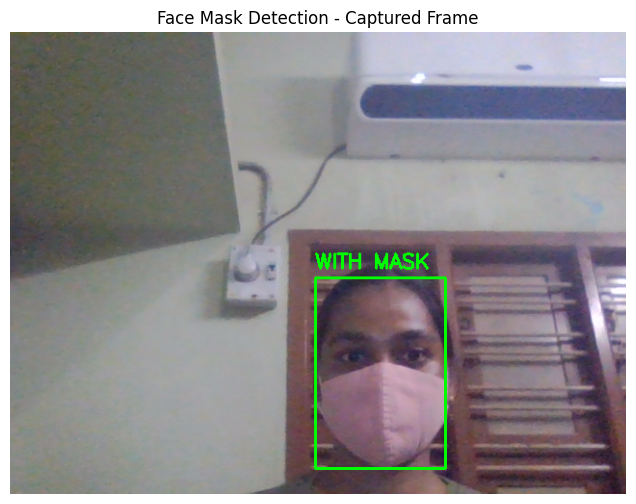

In [22]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from collections import deque
from tensorflow.keras.models import load_model
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Load the trained MobileNetV2 model
model=load_model("face_mask_detector.keras")

# Open webcam
cap=cv2.VideoCapture(0)

if not cap.isOpened():
    raise RuntimeError("Webcam could not be opened.")

predictions=deque(maxlen=5)
captured_frame=None

try:
    while True:
        ret,frame=cap.read()

        if not ret:
            break

        h,w=frame.shape[:2]

        # Detect human faces
        blob=cv2.dnn.blobFromImage(frame,1.0,(300,300),(104,177,123))

        face_net.setInput(blob)
        detections=face_net.forward()

        for i in range(detections.shape[2]):
            confidence=detections[0,0,i,2]

            if confidence<0.6:
                continue

            box=detections[0,0,i,3:7]*np.array([w,h,w,h])
            x1,y1,x2,y2=box.astype(int)

            # Expand face area to include the mask
            fw=x2-x1
            fh=y2-y1
            size=int(max(fw,fh)*1.35)

            cx=(x1+x2)//2
            cy=int(y1+fh*0.58)

            left=max(0,cx-size//2)
            top=max(0,cy-size//2)
            right=min(w,left+size)
            bottom=min(h,top+size)

            face=frame[top:bottom,left:right]

            if face.size==0:
                continue

            face=cv2.cvtColor(face,cv2.COLOR_BGR2RGB)
            face=cv2.resize(face,(224,224))
            face=preprocess_input(np.expand_dims(face.astype(np.float32),axis=0))

            prediction=model.predict(face,verbose=0)[0][0]
            predictions.append(prediction)

            avg_prediction=np.mean(predictions)

            if avg_prediction>=0.5:
                label="WITHOUT MASK"
            else:
                label="WITH MASK"

            color=(0,0,255) if avg_prediction>=0.5 else (0,255,0)

            cv2.rectangle(frame,(x1,y1),(x2,y2),color,2)
            cv2.putText(frame,label,(x1,max(30,y1-10)),cv2.FONT_HERSHEY_SIMPLEX,0.7,color,2)

        captured_frame=frame.copy()

        cv2.imshow("Face Mask Detection - Press Q to Exit", frame)

        if cv2.waitKey(1)&0xFF==ord("q"):
            break

finally:
    cap.release()
    cv2.destroyAllWindows()

# Display the captured frame in Jupyter Notebook
if captured_frame is not None:
    captured_frame=cv2.cvtColor(captured_frame,cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(10,6))
    plt.imshow(captured_frame)
    plt.axis("off")
    plt.title("Face Mask Detection - Captured Frame")
    plt.show()

# Question 5: Custom Transfer Learning with Frozen + Trainable Layers
### Load a pretrained MobileNetV2 model, freeze base layers, add custom classifier, and fine-tune the top few layers.

In [24]:
# Set Up the Dataset Path
from pathlib import Path
q5_dir=Path("Dataset/Q5_MobileNetV2")

In [25]:
# Load and Preprocess the Flower Dataset
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE=224
BATCH_SIZE=32

data_dir=q5_dir/"flower_photos"

datagen=ImageDataGenerator(preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input,validation_split=0.2)

train_data=datagen.flow_from_directory(str(data_dir),target_size=(IMG_SIZE,IMG_SIZE),batch_size=BATCH_SIZE,
                                       class_mode="categorical",subset="training",shuffle=True)
val_data=datagen.flow_from_directory(str(data_dir),target_size=(IMG_SIZE,IMG_SIZE),batch_size=BATCH_SIZE,
                                     class_mode="categorical",subset="validation",shuffle=False)

print("Class Labels:", train_data.class_indices)

Found 2939 images belonging to 5 classes.
Found 731 images belonging to 5 classes.
Class Labels: {'daisy': 0, 'dandelion': 1, 'roses': 2, 'sunflowers': 3, 'tulips': 4}


In [26]:
# Build MobileNetV2 Model with Custom Classifier
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout

base_model=MobileNetV2(weights="imagenet",include_top=False,input_shape=(224,224,3))
base_model.trainable=False

model=Sequential([base_model,
                  GlobalAveragePooling2D(),
                  Dense(128,activation="relu"),
                  Dropout(0.3),
                  Dense(5,activation="softmax")])
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │         163,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 5)                   │             645 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,422,597 (9.24 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [27]:
# Compile the Model
model.compile(optimizer="adam",loss="categorical_crossentropy",metrics=["accuracy"])

In [28]:
# Train the Custom Classifier
history=model.fit(train_data,validation_data=val_data,epochs=5,verbose=2)

Epoch 1/5
92/92 - 279s - 3s/step - accuracy: 0.7904 - loss: 0.5733 - val_accuracy: 0.8523 - val_loss: 0.3821
Epoch 2/5
92/92 - 199s - 2s/step - accuracy: 0.9034 - loss: 0.2913 - val_accuracy: 0.8796 - val_loss: 0.3489
Epoch 3/5
92/92 - 193s - 2s/step - accuracy: 0.9262 - loss: 0.2044 - val_accuracy: 0.8878 - val_loss: 0.3427
Epoch 4/5
92/92 - 232s - 3s/step - accuracy: 0.9435 - loss: 0.1613 - val_accuracy: 0.8988 - val_loss: 0.3164
Epoch 5/5
92/92 - 184s - 2s/step - accuracy: 0.9592 - loss: 0.1173 - val_accuracy: 0.8796 - val_loss: 0.3384


In [29]:
# Unfreeze the Top Layers for Fine-Tuning
base_model.trainable=True

for layer in base_model.layers[:-20]:
    layer.trainable=False

for layer in base_model.layers[-20:]:
    if isinstance(layer,tf.keras.layers.BatchNormalization):
        layer.trainable=False

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),loss="categorical_crossentropy",metrics=["accuracy"])

In [30]:
# Fine-tune the MobileNetV2 Model
history_fine=model.fit(train_data,validation_data=val_data,epochs=5,verbose=2)

Epoch 1/5
92/92 - 224s - 2s/step - accuracy: 0.9792 - loss: 0.0732 - val_accuracy: 0.9056 - val_loss: 0.3240
Epoch 2/5
92/92 - 158s - 2s/step - accuracy: 0.9850 - loss: 0.0550 - val_accuracy: 0.9042 - val_loss: 0.3399
Epoch 3/5
92/92 - 233s - 3s/step - accuracy: 0.9901 - loss: 0.0419 - val_accuracy: 0.8974 - val_loss: 0.3497
Epoch 4/5
92/92 - 160s - 2s/step - accuracy: 0.9922 - loss: 0.0348 - val_accuracy: 0.9070 - val_loss: 0.3366
Epoch 5/5
92/92 - 200s - 2s/step - accuracy: 0.9918 - loss: 0.0272 - val_accuracy: 0.9001 - val_loss: 0.3467


In [31]:
# Save the Fine-Tuned Model
model.save(q5_dir/"flower_mobilenetv2_finetuned.keras")
print("Fine-tuned model saved successfully.")

Fine-tuned model saved successfully.


In [32]:
# Evaluate the Fine-Tuned Model
val_loss,val_accuracy=model.evaluate(val_data,verbose=2)

print("Validation Loss:", val_loss)
print("Validation Accuracy:", round(val_accuracy*100,2),"%")

23/23 - 29s - 1s/step - accuracy: 0.9001 - loss: 0.3467
Validation Loss: 0.3466697633266449
Validation Accuracy: 90.01 %
